# KMeans statistical-arbitrage reproduction

This notebook separates two portfolio rules applied to the **same** saved daily KMeans signals. A row labelled `signal_date=t` uses information through the close of `t`; its raw `payoff_return` is realised at `t+1`. No cell shifts returns again.

1. **Original repository rule.** The reproduced `naive_stream` strategy signs the raw signal, equal weights each side, and therefore has gross exposure two. Its PnL uses the saved raw next-day stock returns.
2. **Continuous rule.** We instead winsorize each day's raw-signal cross-section at 1% on both tails, z-score it, de-mean it, and L1-normalize it to gross one and net zero. Its PnL also uses raw next-day stock returns.
3. **Decile diagnostic.** D1–D10 and the gross-one long-D1/short-D10 portfolio use **next-day market-excess returns**: each stock's raw `t+1` return less the Top-500, `DlyCap[t]`-weighted market return. This makes the decile plot comparable to the Graph-local decile diagnostic while preserving the original KMeans results above.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline


def project_root() -> Path:
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "data").is_dir() and (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the project root")


ROOT = project_root()
sys.path.insert(0, str(ROOT / "local"))
from decile_analysis import (
    cumulative_log_returns,
    decile_portfolios,
    standardized_long_short_weights,
    weighted_daily_returns,
)

RUN = ROOT / "data/derived/t_aligned_kmeans/market"
BOOKS_PATH = RUN / "kmeans_market_daily_books.csv.gz"
ORIGINAL_PNL_PATH = RUN / "kmeans_market_daily_pnl.csv"
ZSCORE_PNL_PATH = RUN / "kmeans_market_zscore_gross1_daily_pnl.csv"
MARKET_RETURN_PATH = RUN / "kmeans_market_next_day_market_return.csv"

SAMPLE_DATE = "2010-01-04"
PLOT_START = "2010-01-01"       # Use "1997-01-01" for the full KMeans history.
WINSOR = 0.01
REBUILD_ZSCORE_PNL = False       # True recomputes it directly from BOOKS_PATH.

## 1. Original repository trading rule

The daily KMeans partition and continuous raw signal are already contained in the saved book.  The original trading engine maps all positive scores to `+1/n_long`, all negative scores to `-1/n_short`, and exact zeros to zero.  Thus each active side has absolute exposure one: net exposure is zero and gross exposure is two.


In [2]:
books = pd.read_csv(
    BOOKS_PATH,
    compression="gzip",
    parse_dates=["signal_date", "payoff_date"],
    dtype={"permno": str},
)
original_pnl = pd.read_csv(ORIGINAL_PNL_PATH, parse_dates=["signal_date"]).set_index("signal_date")["daily_pnl"]

sample_date = pd.Timestamp(SAMPLE_DATE)
sample = books.loc[books.signal_date.eq(sample_date), ["permno", "raw_signal", "weight", "payoff_return"]]
if sample.empty:
    raise ValueError(f"No saved KMeans book on {sample_date.date()}")

# The extremes make the original sign-and-equal-weight transformation visible.
display(pd.concat([
    sample.sort_values("raw_signal", ascending=False).head(6),
    sample.sort_values("raw_signal", ascending=True).head(6),
]).reset_index(drop=True))

original_exposure = books.groupby("signal_date", sort=True).weight.agg(
    net="sum", gross=lambda x: x.abs().sum(), n_nonzero=lambda x: (x != 0).sum(),
)
display(original_exposure.describe().T)

recreated_original_pnl = (books.weight * books.payoff_return).groupby(books.signal_date, sort=True).sum()
assert np.allclose(recreated_original_pnl.reindex(original_pnl.index), original_pnl, atol=1e-14, rtol=0)
print("The exported weights reproduce the original saved daily PnL exactly.")


,permno,raw_signal,weight,payoff_return
0,HRI.91575,0.055433,0.004016,-0.009259
1,EXPE.90808,0.052450,0.004016,0.004260
2,CFN.92988,0.049524,0.004016,-0.010830
3,RCL.79145,0.045068,0.004016,0.003488
4,AMZN.84788,0.039769,0.004016,0.005900
5,CEG.24221,0.039739,0.004016,-0.007739
6,CEPH.76625,-0.061874,-0.004184,-0.009438
7,CNA.47626,-0.060535,-0.004184,-0.002445
8,MU.53613,-0.049242,-0.004184,0.029493
9,MGA.78045,-0.046910,-0.004184,0.075826


,count,mean,std,min,25%,50%,75%,max
net,6945.0,-5.178233e-16,1.129882e-14,-2.477315e-14,-1.018369e-14,-1.986258e-16,8.861835e-15,2.556462e-14
gross,6945.0,2.000000e+00,9.496694e-15,2.000000e+00,2.000000e+00,2.000000e+00,2.000000e+00,2.000000e+00
n_nonzero,6945.0,4.880009e+02,3.332738e+00,4.700000e+02,4.860000e+02,4.880000e+02,4.900000e+02,4.980000e+02


The exported weights reproduce the original saved daily PnL exactly.


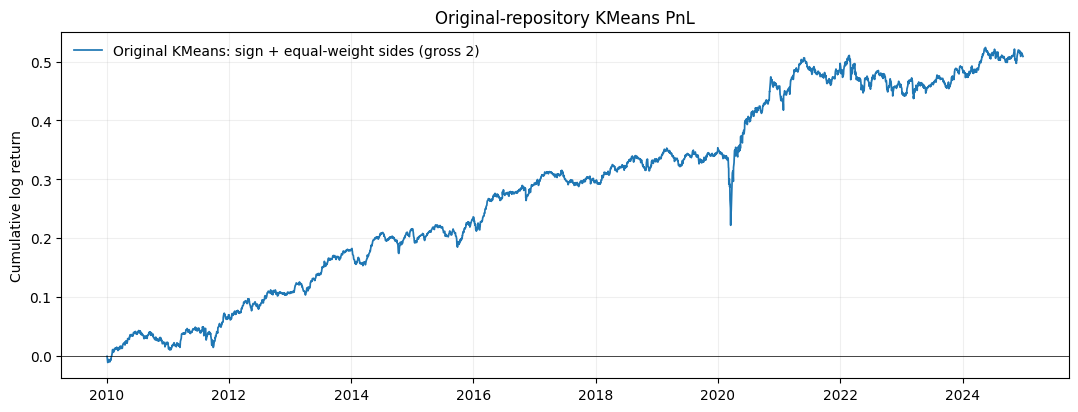

,days,AnnRet,AnnVol,Sharpe,CumLogReturn
series,,,,,
Original KMeans (gross 2),3772,3.49%,4.30%,0.811,0.508
Original KMeans / 2 (gross 1 equivalent),3772,1.74%,2.15%,0.811,0.258


In [3]:
def performance_row(name, daily_return):
    x = daily_return.dropna()
    annual_vol = x.std(ddof=1) * np.sqrt(252)
    return {
        "series": name,
        "days": len(x),
        "AnnRet": x.mean() * 252,
        "AnnVol": annual_vol,
        "Sharpe": (x.mean() * 252) / annual_vol,
        "CumLogReturn": np.log1p(x).sum(),
    }

start = pd.Timestamp(PLOT_START)
original_view = original_pnl.loc[original_pnl.index >= start]
original_curve = cumulative_log_returns(original_view)
original_curve = original_curve - original_curve.iloc[0]

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(original_curve.index, original_curve, lw=1.25, label="Original KMeans: sign + equal-weight sides (gross 2)")
ax.axhline(0, color="black", lw=.5)
ax.set(title="Original-repository KMeans PnL", xlabel="", ylabel="Cumulative log return")
ax.grid(alpha=.2)
ax.legend(frameon=False)
plt.show()

display(pd.DataFrame([
    performance_row("Original KMeans (gross 2)", original_view),
    performance_row("Original KMeans / 2 (gross 1 equivalent)", 0.5 * original_view),
]).set_index("series").style.format({
    "AnnRet": "{:.2%}", "AnnVol": "{:.2%}", "Sharpe": "{:.3f}", "CumLogReturn": "{:.3f}",
}))


## 2. Continuous gross-one/net-zero rule and market-excess deciles

The continuous rule uses the same valid stock set and raw `t+1` realised returns as the original book. It changes only the mapping from `raw_signal` to portfolio weight. Every day it applies: 1% two-sided winsorization → z-score → de-mean → divide by the sum of absolute scores.

The decile sort is also by continuous `raw_signal`, not by the original discrete `+1/n`, `0`, `-1/n` weights. D1 is the highest raw signal; D10 is the lowest. Each displayed decile earns its equal-weight **market-excess** return, subtracting the same Top-500, `DlyCap[t]`-weighted raw `t+1` market return from every constituent. The endpoint portfolio earns `0.5 × D1 − 0.5 × D10`, hence gross one and net zero; the common market benchmark cancels algebraically in that endpoint, but it matters for the individual D1–D10 curves.

In [4]:
if REBUILD_ZSCORE_PNL:
    # Generic implementation: every row is already paired with its raw t+1 payoff.
    zscore_books = standardized_long_short_weights(
        books,
        date_col="signal_date",
        asset_col="permno",
        score_col="raw_signal",
        return_col="payoff_return",
        winsor=WINSOR,
        weight_col="weight",
    )
    zscore_pnl = weighted_daily_returns(zscore_books)
else:
    zscore_pnl = pd.read_csv(ZSCORE_PNL_PATH, parse_dates=["signal_date"]).set_index("signal_date")["daily_pnl"]

# A single date demonstrates the gross-one/net-zero invariant without loading a
# second full book into memory.
one_day_zscore_book = standardized_long_short_weights(
    sample.assign(signal_date=sample_date), winsor=WINSOR,
)
one_day_exposure = one_day_zscore_book.weight.agg(net="sum", gross=lambda x: x.abs().sum())
display(one_day_zscore_book.sort_values("weight", ascending=False).head(6)[["permno", "raw_signal", "weight", "payoff_return"]])
display(one_day_exposure.to_frame("value"))
assert np.isclose(one_day_exposure["net"], 0.0, atol=1e-12)
assert np.isclose(one_day_exposure["gross"], 1.0, atol=1e-12)

# The market benchmark is built from the same Top-500 universe: DlyCap[t]
# selects and weights securities, while raw return t+1 is realised. It joins
# one benchmark row to every contemporaneous stock-level KMeans row.
market_returns = pd.read_csv(
    MARKET_RETURN_PATH,
    parse_dates=["signal_date", "payoff_date"],
)
if market_returns.duplicated(["signal_date", "payoff_date"]).any():
    raise ValueError("Market benchmark contains duplicate signal/payoff dates")
decile_books = books.merge(
    market_returns,
    on=["signal_date", "payoff_date"],
    how="left",
    validate="many_to_one",
)
if decile_books.market_return.isna().any():
    missing = decile_books.loc[decile_books.market_return.isna(), "signal_date"].nunique()
    raise ValueError(f"Market benchmark is missing for {missing} signal dates")
decile_books["market_excess_return"] = decile_books.payoff_return - decile_books.market_return

# Each decile is equal-weight long-only. D1-D10 applies +0.5/-0.5.
deciles = decile_portfolios(
    decile_books,
    date_col="signal_date",
    asset_col="permno",
    return_col="market_excess_return",
    score_col="raw_signal",
    higher_is_decile_1=True,
)

,permno,raw_signal,weight,payoff_return
448,RCL.79145,0.045068,0.006218,0.003488
479,HRI.91575,0.055433,0.006218,-0.009259
377,EXPE.90808,0.052450,0.006218,0.004260
37,AMZN.84788,0.039769,0.006218,0.005900
447,CFN.92988,0.049524,0.006218,-0.010830
369,CEG.24221,0.039739,0.006218,-0.007739


,value
net,-2.081668e-17
gross,1.000000e+00


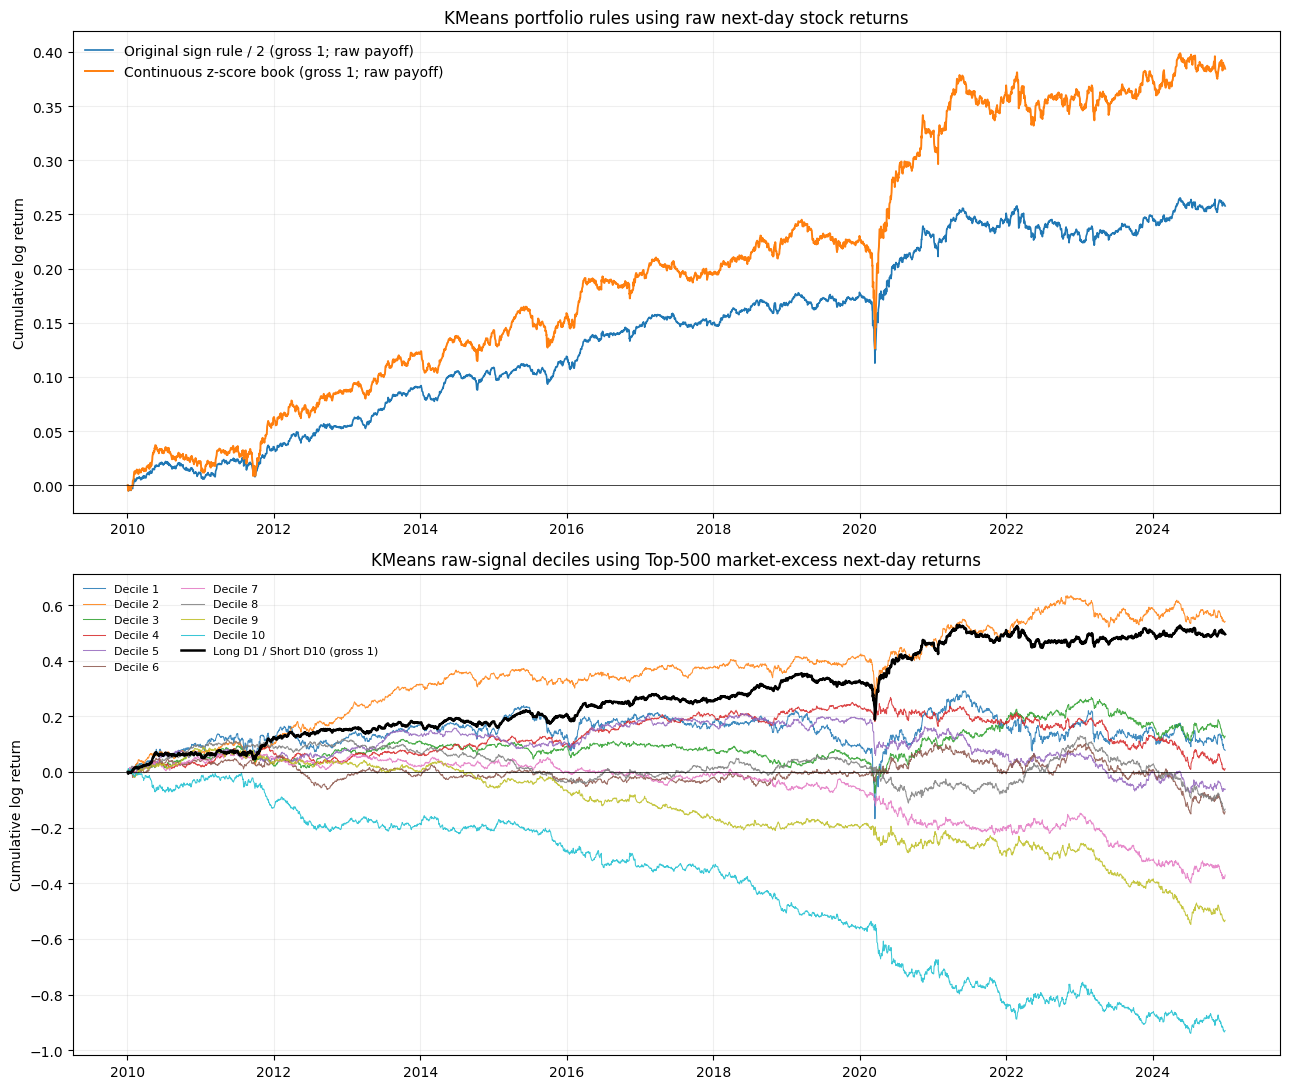

Raw-return portfolio metrics


,days,AnnRet,AnnVol,Sharpe,CumLogReturn
series,,,,,
Original KMeans / 2 (gross 1; raw payoff),3772,1.74%,2.15%,0.811,0.258
Continuous z-score (gross 1; raw payoff),3772,2.62%,3.46%,0.759,0.384


Market-excess decile metrics


,days,AnnRet,AnnVol,Sharpe,CumLogReturn
series,,,,,
Decile 1 (market excess),3772,0.88%,8.49%,0.104,0.078
Decile 10 (market excess),3772,-5.98%,6.79%,-0.880,-0.929
Long D1 / short D10 (gross 1; market excess),3772,3.43%,4.94%,0.694,0.495


,count,mean,std,min,25%,50%,75%,max
decile_1,3772.0,50.000000,0.000000,50.0,50.0,50.0,50.0,50.0
decile_2,3772.0,50.000000,0.000000,50.0,50.0,50.0,50.0,50.0
decile_3,3772.0,49.995758,0.064999,49.0,50.0,50.0,50.0,50.0
decile_4,3772.0,49.985154,0.120953,49.0,50.0,50.0,50.0,50.0
decile_5,3772.0,49.958643,0.199142,49.0,50.0,50.0,50.0,50.0
decile_6,3772.0,49.884942,0.319135,49.0,50.0,50.0,50.0,50.0
decile_7,3772.0,49.783669,0.411797,49.0,50.0,50.0,50.0,50.0
decile_8,3772.0,49.585631,0.492678,49.0,49.0,50.0,50.0,50.0
decile_9,3772.0,49.336691,0.472641,49.0,49.0,49.0,50.0,50.0
decile_10,3772.0,49.088547,0.284127,49.0,49.0,49.0,49.0,50.0


In [5]:
zscore_view = zscore_pnl.loc[zscore_pnl.index >= start]
original_gross_one_view = 0.5 * original_view
ls_view = deciles.daily_returns.loc[lambda x: x.index >= start, "long_decile_1_short_decile_10"]

zscore_curve = cumulative_log_returns(zscore_view)
zscore_curve = zscore_curve - zscore_curve.iloc[0]
original_gross_one_curve = cumulative_log_returns(original_gross_one_view)
original_gross_one_curve = original_gross_one_curve - original_gross_one_curve.iloc[0]
ls_curve = cumulative_log_returns(ls_view)
ls_curve = ls_curve - ls_curve.iloc[0]

decile_view = deciles.cumulative_log_returns.loc[lambda x: x.index >= start]
decile_view = decile_view - decile_view.iloc[0]

fig, axes = plt.subplots(2, 1, figsize=(13, 11))
axes[0].plot(original_gross_one_curve.index, original_gross_one_curve, lw=1.2, label="Original sign rule / 2 (gross 1; raw payoff)")
axes[0].plot(zscore_curve.index, zscore_curve, lw=1.4, label="Continuous z-score book (gross 1; raw payoff)")
axes[0].axhline(0, color="black", lw=.5)
axes[0].set(title="KMeans portfolio rules using raw next-day stock returns", xlabel="", ylabel="Cumulative log return")
axes[0].grid(alpha=.2)
axes[0].legend(frameon=False)

# D1 through D10 use each stock's return less the Top-500 value-weighted market return.
for column in [f"decile_{i}" for i in range(1, 11)]:
    axes[1].plot(decile_view.index, decile_view[column], lw=.75, alpha=.85, label=column.replace("_", " ").title())
axes[1].plot(decile_view.index, decile_view["long_decile_1_short_decile_10"], color="black", lw=1.8, label="Long D1 / Short D10 (gross 1)")
axes[1].axhline(0, color="black", lw=.5)
axes[1].set(
    title="KMeans raw-signal deciles using Top-500 market-excess next-day returns",
    xlabel="", ylabel="Cumulative log return",
)
axes[1].grid(alpha=.2)
axes[1].legend(ncol=2, fontsize=8, frameon=False)
fig.tight_layout()
plt.show()

raw_comparison = pd.DataFrame([
    performance_row("Original KMeans / 2 (gross 1; raw payoff)", original_gross_one_view),
    performance_row("Continuous z-score (gross 1; raw payoff)", zscore_view),
]).set_index("series")
print("Raw-return portfolio metrics")
display(raw_comparison.style.format({
    "AnnRet": "{:.2%}", "AnnVol": "{:.2%}", "Sharpe": "{:.3f}", "CumLogReturn": "{:.3f}",
}))

excess_comparison = pd.DataFrame([
    performance_row("Decile 1 (market excess)", deciles.daily_returns.loc[lambda x: x.index >= start, "decile_1"]),
    performance_row("Decile 10 (market excess)", deciles.daily_returns.loc[lambda x: x.index >= start, "decile_10"]),
    performance_row("Long D1 / short D10 (gross 1; market excess)", ls_view),
]).set_index("series")
print("Market-excess decile metrics")
display(excess_comparison.style.format({
    "AnnRet": "{:.2%}", "AnnVol": "{:.2%}", "Sharpe": "{:.3f}", "CumLogReturn": "{:.3f}",
}))

display(deciles.holdings.loc[lambda x: x.index >= start].describe().T)